In [197]:
import pandas as pd
import numpy as np

In [198]:
data = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv'

In [39]:
!wget $data

--2026-10-16 14:44:48--  https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 635180 (620K) [text/plain]
Saving to: ‘car_fuel_efficiency_2026.csv’

car_fuel_efficiency 100%[===================>] 620.29K  --.-KB/s    in 0.004s  

2026-10-16 14:44:49 (164 MB/s) - ‘car_fuel_efficiency_2026.csv’ saved [635180/635180]



In [466]:
df = pd.read_csv('car_fuel_efficiency_2026.csv')
df.head()

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0


In [467]:
del df['acceleration']
del df['origin']
del df['fuel_type']
del df['drivetrain']
del df['num_doors']
del df['num_cylinders']

In [468]:
df['model_year'].max()

np.int64(2024)

In [469]:
df


,model_year,engine_displacement,horsepower,vehicle_weight,fuel_efficiency_mpg
0,2006,2180,243.0,3870,31.9
1,2008,2390,272.0,4210,31.3
2,1996,2320,267.0,4240,27.5
3,1989,2130,258.0,4490,28.5
4,1994,2580,304.0,4510,31.0
...,...,...,...,...,...
9995,2005,2470,271.0,4690,27.4
9996,1993,2300,244.0,4370,30.0
9997,2014,2480,267.0,4590,28.1
9998,2004,2180,270.0,4450,32.2


In [470]:
df.columns = df.columns.str.lower().str.replace(' ', '_')

In [471]:
strings = list(df.dtypes[df.dtypes == 'str'].index)
strings

[]

In [472]:
for col in strings:
    df[col] = df[col].str.lower().str.replace(' ', '_')

In [473]:
df.head()

,model_year,engine_displacement,horsepower,vehicle_weight,fuel_efficiency_mpg
0,2006,2180,243.0,3870,31.9
1,2008,2390,272.0,4210,31.3
2,1996,2320,267.0,4240,27.5
3,1989,2130,258.0,4490,28.5
4,1994,2580,304.0,4510,31.0


In [474]:
df.dtypes

model_year               int64
engine_displacement      int64
horsepower             float64
vehicle_weight           int64
fuel_efficiency_mpg    float64
dtype: object

In [475]:
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

<Axes: xlabel='fuel_efficiency_mpg', ylabel='Count'>

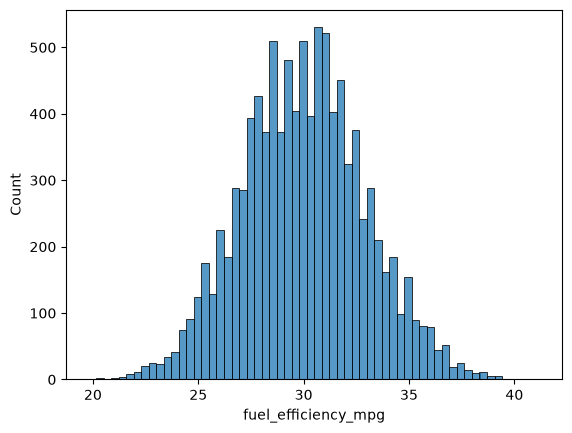

In [476]:
sns.histplot(df.fuel_efficiency_mpg)

In [477]:
df.isnull().sum()

model_year               0
engine_displacement      0
horsepower             877
vehicle_weight           0
fuel_efficiency_mpg      0
dtype: int64

In [478]:
df.horsepower.describe()

count    9123.000000
mean      254.446016
std        22.844613
min       171.000000
25%       239.000000
50%       254.000000
75%       270.000000
max       334.000000
Name: horsepower, dtype: float64

In [479]:
df['horsepower'] = df['horsepower'].fillna(0)
df.isnull().sum()

model_year             0
engine_displacement    0
horsepower             0
vehicle_weight         0
fuel_efficiency_mpg    0
dtype: int64

In [388]:
n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(42)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train + n_val]]
df_test = df.iloc[idx[n_train + n_val:]]

In [389]:
len(df_train), len(df_val), len(df_test)

(6000, 2000, 2000)

In [390]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [391]:
y_train = df_train['fuel_efficiency_mpg'].values
y_val = df_val['fuel_efficiency_mpg'].values
y_test = df_test['fuel_efficiency_mpg'].values

In [392]:
del df_train['fuel_efficiency_mpg']
del df_val['fuel_efficiency_mpg']
del df_test['fuel_efficiency_mpg']

In [393]:
df_train.columns

Index(['model_year', 'engine_displacement', 'horsepower', 'vehicle_weight'], dtype='str')

In [394]:
df.dtypes


model_year               int64
engine_displacement      int64
horsepower             float64
vehicle_weight           int64
fuel_efficiency_mpg    float64
dtype: object

In [395]:
def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)
    
    return w_full[0], w_full[1:]

In [396]:
base = ['model_year', 'engine_displacement', 'horsepower', 'vehicle_weight']
X_train = df_train[base].fillna(0).values

w0, w = train_linear_regression(X_train, y_train)

y_pred = w0 + X_train.dot(w)

In [397]:
def prepare_X(df):
    df_num = df[base]
    df_num = df_num.fillna(0)
    X = df_num.values
    return X

In [398]:
def rmse(y, y_pred):
    se = (y - y_pred) ** 2
    mse = se.mean()
    return np.sqrt(mse)

In [399]:
X_train = prepare_X(df_train)
w0, w = train_linear_regression(X_train, y_train)

X_val = prepare_X(df_val)
y_pred = w0 + X_val.dot(w)
rmse(y_val, y_pred)

np.float64(2.2052931947519787)

with 0 rmse = 2.2052
with mean rmse = 2.2017

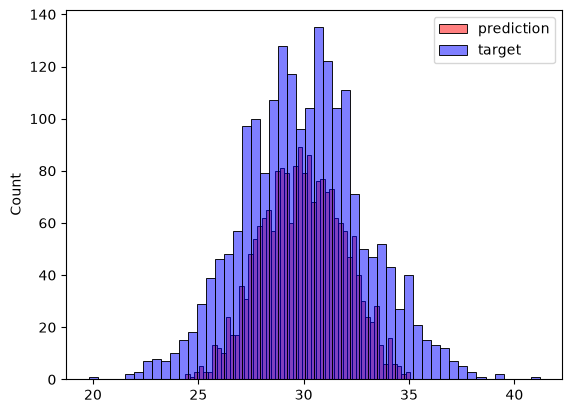

In [400]:
sns.histplot(y_pred, label='prediction', color='red', alpha=0.5, bins=50)
sns.histplot(y_val, label='target', color='blue',  alpha=0.5, bins=50)
plt.legend()

In [402]:
def train_linear_regression_reg(X, y, r=0.001):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX = XTX + r * np.eye(XTX.shape[0])

    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)
    
    return w_full[0], w_full[1:]

In [406]:
for r in [0, 0.01, 0.1, 1, 5, 10, 100]:
    X_train = prepare_X(df_train)
    w0, w = train_linear_regression_reg(X_train, y_train, r=r)

    X_val = prepare_X(df_val)
    y_pred = w0 + X_val.dot(w)
    score = rmse(y_val, y_pred).round(4)
    
    print(r, w0, score)

0 -153.88496188259973 2.2053
0.01 -148.30921244153726 2.2058
0.1 -111.83871039261179 2.2241
1 -32.33186596513985 2.3492
5 -7.772852209918256 2.4094
10 -3.987116416100428 2.4195
100 -0.4082196490160378 2.4292


In [488]:
n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

for s in [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]:
    np.random.seed(s)
    idx = np.arange(n)
    np.random.shuffle(idx)
    
    df_train = df.iloc[idx[:n_train]]
    df_val = df.iloc[idx[n_train:n_train + n_val]]
    df_test = df.iloc[idx[n_train + n_val:]]
    
    
    X_train = prepare_X(df_train)
    w0, w = train_linear_regression(X_train, y_train)
    X_val = prepare_X(df_val)
    y_pred = w0 + X_val.dot(w)
    rmse(y_val, y_pred)
    score = rmse(y_val, y_pred)
    print(score)

2.890934561189793
2.8892526250459833
2.889946028120855
2.8889068936576177
2.8893034523953878
2.8899418885902284
2.890101460495167
2.8912812335489857
2.8911743320662397
2.889504743615346


In [489]:
a = [2.890934561189793,
2.8892526250459833,
2.889946028120855,
2.8889068936576177,
2.8893034523953878,
2.8899418885902284,
2.890101460495167,
2.8912812335489857,
2.8911743320662397,
2.889504743615346]

In [490]:
std = np.std(a)
std

np.float64(0.0007989027552471544)

In [456]:
round(std,3)

np.float64(0.001)

In [480]:
n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test


np.random.seed(9)
idx = np.arange(n)
np.random.shuffle(idx)
    
df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train + n_val]]
df_test = df.iloc[idx[n_train + n_val:]]

In [481]:
df_full_train = pd.concat([df_train, df_val])

In [482]:
df_full_train = df_full_train.reset_index(drop=True)

In [483]:
X_full_train = prepare_X(df_full_train)

In [484]:
X_full_train

array([[2014., 2320.,  246., 4100.],
       [1998., 2230.,  252., 4250.],
       [2008., 2700.,  276., 4490.],
       ...,
       [1994., 1800.,  225., 3980.],
       [2009., 1970.,  232., 3560.],
       [2018., 2180.,  254., 3970.]], shape=(8000, 4))

In [485]:
y_full_train = np.concatenate([y_train, y_val])

In [486]:
w0, w = train_linear_regression_reg(X_full_train, y_full_train, r=0.001)

In [487]:
X_test = prepare_X(df_test)
y_pred = w0 + X_test.dot(w)
score = rmse(y_test, y_pred)
score

np.float64(2.956005314227216)